# AICS-202 | Laboratory 03
## Training Data Poisoning and Dataset Integrity
Course module: 3 | Suggested duration: 4 hours

**Objective:** measure how deliberately corrupted labels in a local training dataset affect a supervised model. This lab never changes external datasets or services.

**Scope:** simple random label corruption is an introductory poisoning simulation, not a realistic targeted backdoor.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
digits = load_digits()
X = digits.data.astype(float) / 16.0
y = digits.target.astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

def build_model(train_features, train_labels):
    model = LogisticRegression(max_iter=600, random_state=SEED)
    model.fit(train_features, train_labels)
    return model

model = build_model(X_train, y_train)
print('Dataset:', X.shape, '| Train:', len(X_train), '| Test:', len(X_test))
print('Clean test accuracy:', round(accuracy_score(y_test, model.predict(X_test)), 4))

Dataset: (1797, 64) | Train: 1347 | Test: 450
Clean test accuracy: 0.9622


Corruption 0%: 0 labels changed | Clean test accuracy 0.962 | label hash ee47679cf3fe
Corruption 5%: 67 labels changed | Clean test accuracy 0.960 | label hash c50002482df8
Corruption 10%: 135 labels changed | Clean test accuracy 0.958 | label hash 40ea3e374687


Corruption 20%: 269 labels changed | Clean test accuracy 0.933 | label hash 19b7e73d459d
Test labels unchanged (SHA-256 verified).


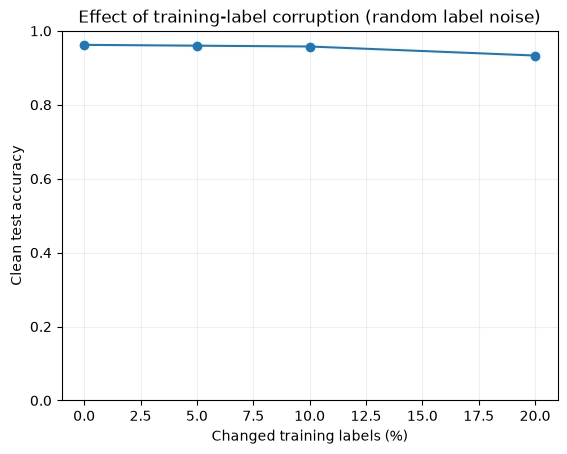

In [2]:
# Required levels 0/5/10/20 %, training split ONLY; test labels untouched. Poisoning seed = 2026.
import csv, os, hashlib
os.makedirs('results', exist_ok=True)
from sklearn.metrics import confusion_matrix
y_test_fingerprint = hashlib.sha256(y_test.tobytes()).hexdigest()
rng = np.random.default_rng(2026)
corruption_levels = [0.00, 0.05, 0.10, 0.20]
records = []
for fraction in corruption_levels:
    labels_changed = y_train.copy()
    n = round(len(labels_changed)*fraction)
    selected = rng.choice(len(labels_changed), size=n, replace=False)
    # Replace with a *different* label; this simulates integrity compromise.
    labels_changed[selected] = (labels_changed[selected] + rng.integers(1, 10, size=n)) % 10
    assert (labels_changed[selected] != y_train[selected]).all()           # every touched label really changed
    assert (labels_changed != y_train).sum() == n                           # nothing else changed
    tested_model = build_model(X_train, labels_changed)
    accuracy = accuracy_score(y_test, tested_model.predict(X_test))
    records.append((fraction, n, accuracy))
    print(f'Corruption {fraction:.0%}: {n} labels changed | Clean test accuracy {accuracy:.3f} | label hash {hashlib.sha256(labels_changed.tobytes()).hexdigest()[:12]}')
assert hashlib.sha256(y_test.tobytes()).hexdigest() == y_test_fingerprint   # test labels never modified
print('Test labels unchanged (SHA-256 verified).')
base_acc = records[0][2]
with open('results/E05_label_corruption_results.csv', 'w', newline='') as f:
    w = csv.writer(f); w.writerow(['corruption_rate', 'labels_changed', 'clean_test_accuracy', 'drop_percentage_points'])
    for fr, n, a in records: w.writerow([fr, n, round(a, 4), round(100*(base_acc-a), 1)])
plt.plot([r[0]*100 for r in records], [r[2] for r in records], 'o-')
plt.xlabel('Changed training labels (%)'); plt.ylabel('Clean test accuracy')
plt.title('Effect of training-label corruption (random label noise)');plt.ylim(0,1);plt.grid(alpha=.2)
plt.savefig('results/E05_label_corruption_curve.png', dpi=200, bbox_inches='tight'); plt.show()

rate | mean acc | min | max   (5 seeds)
  0% | 0.962 | 0.962 | 0.962
  5% | 0.957 | 0.944 | 0.967
 10% | 0.954 | 0.949 | 0.960
 20% | 0.943 | 0.929 | 0.960
 30% | 0.927 | 0.922 | 0.938
 40% | 0.904 | 0.889 | 0.920
 50% | 0.864 | 0.827 | 0.896


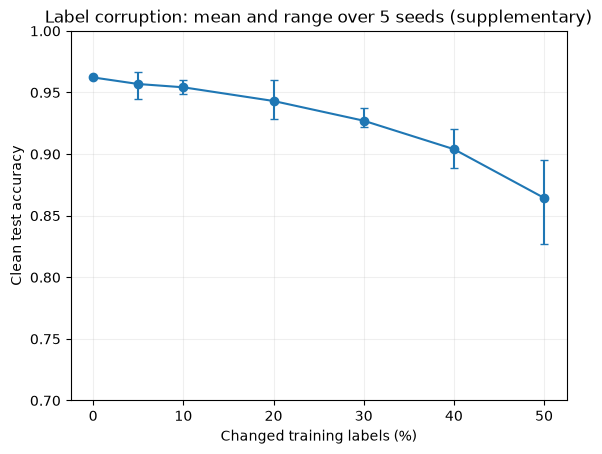

In [3]:
# ADDED CELL (supplementary): is the trend noisy? Repeat with 5 poisoning seeds and an extended range.
# Seed 2026 above is the primary result; these repeats only show seed-to-seed spread.
levels = [0.00, 0.05, 0.10, 0.20, 0.30, 0.40, 0.50]
seeds = [2026, 2027, 2028, 2029, 2030]
table = {lv: [] for lv in levels}
for s in seeds:
    for lv in levels:
        r = np.random.default_rng([s, int(lv*100)])
        lab = y_train.copy(); n = round(len(lab)*lv)
        idx = r.choice(len(lab), size=n, replace=False)
        lab[idx] = (lab[idx] + r.integers(1, 10, size=n)) % 10
        table[lv].append(accuracy_score(y_test, build_model(X_train, lab).predict(X_test)))
print('rate | mean acc | min | max   (5 seeds)')
for lv in levels:
    a = np.array(table[lv]); print(f'{lv:4.0%} | {a.mean():.3f} | {a.min():.3f} | {a.max():.3f}')
m = [np.mean(table[lv]) for lv in levels]; lo = [np.min(table[lv]) for lv in levels]; hi = [np.max(table[lv]) for lv in levels]
plt.errorbar([l*100 for l in levels], m, yerr=[np.array(m)-lo, np.array(hi)-m], fmt='o-', capsize=3)
plt.xlabel('Changed training labels (%)'); plt.ylabel('Clean test accuracy'); plt.ylim(0.7,1.0); plt.grid(alpha=.2)
plt.title('Label corruption: mean and range over 5 seeds (supplementary)')
plt.savefig('results/E05b_label_corruption_seeds.png', dpi=200, bbox_inches='tight'); plt.show()

### Part B - Create a data integrity checklist
Prepare a controls table for dataset provenance, cryptographic hashes, label audits, role-restricted writes, staged approval, and anomaly review.

**Student exercises:**
- Explain why training data is a security asset.
- Compare control results and explain any non-monotonic accuracy changes.
- Propose three technical and two procedural safeguards.

**Deliverables:** plot, results table, explanation and a signed-off integrity checklist for this hypothetical dataset.